# GMM 2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import ndimage as ndi
from scipy.stats import norm

from sklearn.mixture import GaussianMixture
from skimage import io, filters, morphology, measure
from skimage.color import rgb2gray

In [2]:
# =====================================================
# 1. PARAMETERS
# =====================================================

image_paths = [
    "img1.tif",
    "img2.tif",
    "img3.tif",
    "img4.tif"
]

output_dir = Path("GMM_refined_segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

# Image preprocessing
sigma = 1.2

# GMM parameters
n_components = 3
random_state = 42
n_init = 10
max_iter = 300
max_fit_pixels = None

# Initial segmentation
min_area = 3
connectivity = 2

# Local ROI refinement
alpha = 0.15
background_percentile = 10
refined_min_area = 20

# Visualization
show_plots = True

In [9]:
# =====================================================
# 2. LOAD IMAGE
# =====================================================

def load_image(image_path):

    image = io.imread(image_path)

    if image.ndim == 3 and image.shape[-1] in (3, 4):
        image = rgb2gray(image[..., :3])

    if image.ndim != 2:
        raise ValueError(
            f"Expected a 2D image, got {image.shape}"
        )

    image = image.astype(np.float64)

    if not np.isfinite(image).all():
        raise ValueError("Image contains NaN or Inf")

    imin = image.min()
    imax = image.max()

    if imax <= imin:
        raise ValueError("Image has constant intensity")

    image = (image - imin) / (imax - imin)

    return image


# =====================================================
# 3. FIT GMM
# =====================================================

def fit_gmm(image):

    pixels = image.reshape(-1, 1)

    if (
        max_fit_pixels is not None
        and len(pixels) > max_fit_pixels
    ):

        rng = np.random.default_rng(random_state)

        indices = rng.choice(
            len(pixels),
            size=max_fit_pixels,
            replace=False
        )

        fit_pixels = pixels[indices]

    else:
        fit_pixels = pixels

    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type="full",
        random_state=random_state,
        n_init=n_init,
        max_iter=max_iter,
        reg_covar=1e-6
    )

    gmm.fit(fit_pixels)

    return gmm


# =====================================================
# 4. EXTRACT GMM PARAMETERS
# =====================================================

def get_gmm_parameters(gmm):

    means = gmm.means_.flatten()
    stds = np.sqrt(gmm.covariances_.reshape(-1))
    weights = gmm.weights_

    order = np.argsort(means)

    return (
        means[order],
        stds[order],
        weights[order]
    )


# =====================================================
# 5. GMM THRESHOLD
# =====================================================

def find_gmm_threshold(gmm, means, grid_size=10000):

    intensity_grid = np.linspace(0, 1, grid_size)

    probabilities = gmm.predict_proba(
        intensity_grid.reshape(-1, 1)
    )

    brightest_component = np.argmax(
        gmm.means_.flatten()
    )

    predicted_components = np.argmax(
        probabilities,
        axis=1
    )

    candidate_indices = np.where(
        (intensity_grid >= means[-2])
        & (predicted_components == brightest_component)
    )[0]

    if len(candidate_indices) == 0:
        raise ValueError(
            "No high-intensity GMM decision region found."
        )

    return intensity_grid[candidate_indices[0]]


# =====================================================
# 6. INITIAL SEGMENTATION
# =====================================================

def segment_image(smooth, threshold):

    mask = smooth > threshold

    mask = ndi.binary_fill_holes(mask)

    mask = morphology.remove_small_objects(
        mask,
        min_size=min_area,
        connectivity=connectivity
    )

    labels = measure.label(
        mask,
        connectivity=connectivity
    )

    return mask, labels


# =====================================================
# 7. LOCAL ROI REFINEMENT
# =====================================================

def refine_gmm_rois(
    smooth,
    labels,
    alpha=0.35,
    min_area=1,
    background_percentile=10
):
    """
    Shrink each detected ROI using its own intensity range.

    alpha = 0: retain the original ROI
    alpha > 0: shrink toward the brightest region

    The brightest connected component is retained
    for each original ROI.
    """

    refined_labels = np.zeros(
        labels.shape,
        dtype=np.int32
    )

    next_label = 1

    for region in measure.regionprops(labels):

        minr, minc, maxr, maxc = region.bbox

        local_image = smooth[
            minr:maxr,
            minc:maxc
        ]

        local_roi = (
            labels[minr:maxr, minc:maxc]
            == region.label
        )

        intensities = local_image[local_roi]

        if len(intensities) == 0:
            continue

        # Intensity reference within the original ROI
        background = np.percentile(
            intensities,
            background_percentile
        )

        peak = np.max(intensities)

        # Local threshold
        local_threshold = (
            background
            + alpha * (peak - background)
        )

        # Keep only brighter pixels inside this ROI
        refined = (
            local_roi
            & (local_image >= local_threshold)
        )

        # Label connected regions
        components = measure.label(
            refined,
            connectivity=connectivity
        )

        # Locate the brightest pixel of the original ROI
        peak_position = np.unravel_index(
            np.argmax(
                np.where(
                    local_roi,
                    local_image,
                    -np.inf
                )
            ),
            local_image.shape
        )

        peak_label = components[peak_position]

        if peak_label == 0:
            continue

        # Keep the component containing the peak
        refined = components == peak_label

        if np.count_nonzero(refined) < min_area:
            continue

        # Assign a separate label to this ROI
        local_output = refined_labels[
            minr:maxr,
            minc:maxc
        ]

        local_output[refined] = next_label

        next_label += 1

    refined_mask = refined_labels > 0

    return refined_mask, refined_labels


# =====================================================
# 8. DRAW ROI CONTOURS
# =====================================================

def draw_contours(ax, image, labels):

    ax.imshow(
        image,
        cmap="gray",
        interpolation="nearest"
    )

    for region in measure.regionprops(labels):

        roi_mask = labels == region.label

        contours = measure.find_contours(
            np.pad(
                roi_mask.astype(float),
                1,
                mode="constant"
            ),
            level=0.5
        )

        for contour in contours:

            ax.plot(
                contour[:, 1] - 1,
                contour[:, 0] - 1,
                color="red",
                linewidth=0.7
            )

    ax.axis("off")


# =====================================================
# 9. PROCESS ONE IMAGE
# =====================================================

def calculate_common_hist_limits(image_paths):

    all_pixels = []
    all_thresholds = []

    for image_path in image_paths:

        image = load_image(image_path)

        smooth = filters.gaussian(
            image,
            sigma=sigma
        )

        all_pixels.append(smooth.ravel())

        gmm = fit_gmm(smooth)

        means, stds, weights = get_gmm_parameters(gmm)

        threshold = find_gmm_threshold(
            gmm,
            means
        )

        all_thresholds.append(threshold)

    all_pixels = np.concatenate(all_pixels)

    hist_low = min(
        np.percentile(all_pixels, 0.1),
        min(all_thresholds)
    )

    hist_high = max(
        np.percentile(all_pixels, 99.9),
        max(all_thresholds) * 1.15
    )

    hist_low = max(0.0, hist_low)
    hist_high = min(1.0, hist_high)

    if hist_high <= hist_low:
        hist_low, hist_high = 0.0, 1.0

    return hist_low, hist_high


def process_image_gmm(
    image_path,
    plot=True,
    save_path=None,
    hist_xlim=(0.0, 1.0)
):

    image_name = Path(image_path).stem

    # ==============================================
    # 1. LOAD AND SMOOTH
    # ==============================================

    image = load_image(image_path)

    smooth = filters.gaussian(
        image,
        sigma=sigma
    )

    # ==============================================
    # 2. FIT GMM
    # ==============================================

    gmm = fit_gmm(smooth)

    means, stds, weights = get_gmm_parameters(gmm)

    T_gmm = find_gmm_threshold(
        gmm,
        means
    )

    # ==============================================
    # 3. INITIAL SEGMENTATION
    # ==============================================

    initial_mask, initial_labels = segment_image(
        smooth,
        T_gmm
    )

    # ==============================================
    # 4. LOCAL ROI REFINEMENT
    # ==============================================

    refined_mask, refined_labels = refine_gmm_rois(
        smooth,
        initial_labels,
        alpha=alpha,
        min_area=refined_min_area,
        background_percentile=background_percentile
    )

    n_initial = int(initial_labels.max())
    n_refined = int(refined_labels.max())

    # ==============================================
    # 5. COMMON HISTOGRAM RANGE
    # ==============================================

    hist_low, hist_high = hist_xlim

    # ==============================================
    # 6. FINAL VISUALIZATION
    # ==============================================

    if plot or save_path is not None:

        fig, axes = plt.subplots(
            1, 3,
            figsize=(18, 5.5),
            gridspec_kw={
                "width_ratios": [1, 1, 1.4]
            }
        )

        # ------------------------------------------
        # PANEL 1: FINAL BINARY MASK
        # ------------------------------------------

        axes[0].imshow(
            refined_mask,
            cmap="gray",
            interpolation="nearest"
        )

        axes[0].set_title(
            f"Final binary mask\nROIs = {n_refined}",
            fontsize=13,
            fontweight="bold"
        )

        axes[0].axis("off")

        # ------------------------------------------
        # PANEL 2: FINAL SEGMENTATION
        # ------------------------------------------

        draw_contours(
            axes[1],
            image,
            refined_labels
        )

        axes[1].set_title(
            f"Final segmentation\nalpha = {alpha}",
            fontsize=13,
            fontweight="bold"
        )

        # ------------------------------------------
        # PANEL 3: HISTOGRAM
        # ------------------------------------------

        ax = axes[2]

        pixels = smooth.ravel()

        counts, bin_edges = np.histogram(
            pixels,
            bins=150,
            range=(hist_low, hist_high)
        )

        bin_centers = (
            bin_edges[:-1] + bin_edges[1:]
        ) / 2

        bin_widths = np.diff(bin_edges)

        ax.bar(
            bin_centers,
            counts,
            width=bin_widths,
            color="steelblue",
            alpha=0.8,
            edgecolor="none",
            label="Pixel intensity"
        )

        # GMM threshold
        ax.axvline(
            T_gmm,
            color="red",
            linestyle="--",
            linewidth=2,
            label=f"GMM threshold = {T_gmm:.4f}"
        )

        # Logarithmic Y-axis
        ax.set_yscale("log")

        ax.set_xlim(
            hist_low,
            hist_high
        )

        ax.set_xlabel(
            "Normalized pixel intensity",
            fontsize=11
        )

        ax.set_ylabel(
            "Pixel count (log scale)",
            fontsize=11
        )

        ax.set_title(
            "Pixel intensity distribution",
            fontsize=13,
            fontweight="bold"
        )

        ax.grid(
            axis="y",
            which="both",
            alpha=0.2
        )

        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.legend(
            fontsize=9,
            frameon=False
        )

        # ------------------------------------------
        # FIGURE SETTINGS
        # ------------------------------------------

        fig.suptitle(
            image_name,
            fontsize=15,
            fontweight="bold",
            y=1.03
        )

        fig.tight_layout(rect=[0, 0, 1, 0.92])

        if save_path is not None:
            plt.savefig(
                save_path,
                dpi=250,
                bbox_inches="tight"
            )

        if plot:
            plt.show()

        plt.close(fig)

    # ==============================================
    # 7. RETURN RESULTS
    # ==============================================

    return {
        "image": image_name,
        "threshold": T_gmm,
        "means": means,
        "stds": stds,
        "weights": weights,
        "n_initial": n_initial,
        "n_refined": n_refined,
        "initial_mask": initial_mask,
        "initial_labels": initial_labels,
        "refined_mask": refined_mask,
        "refined_labels": refined_labels
    }


Processing: img1


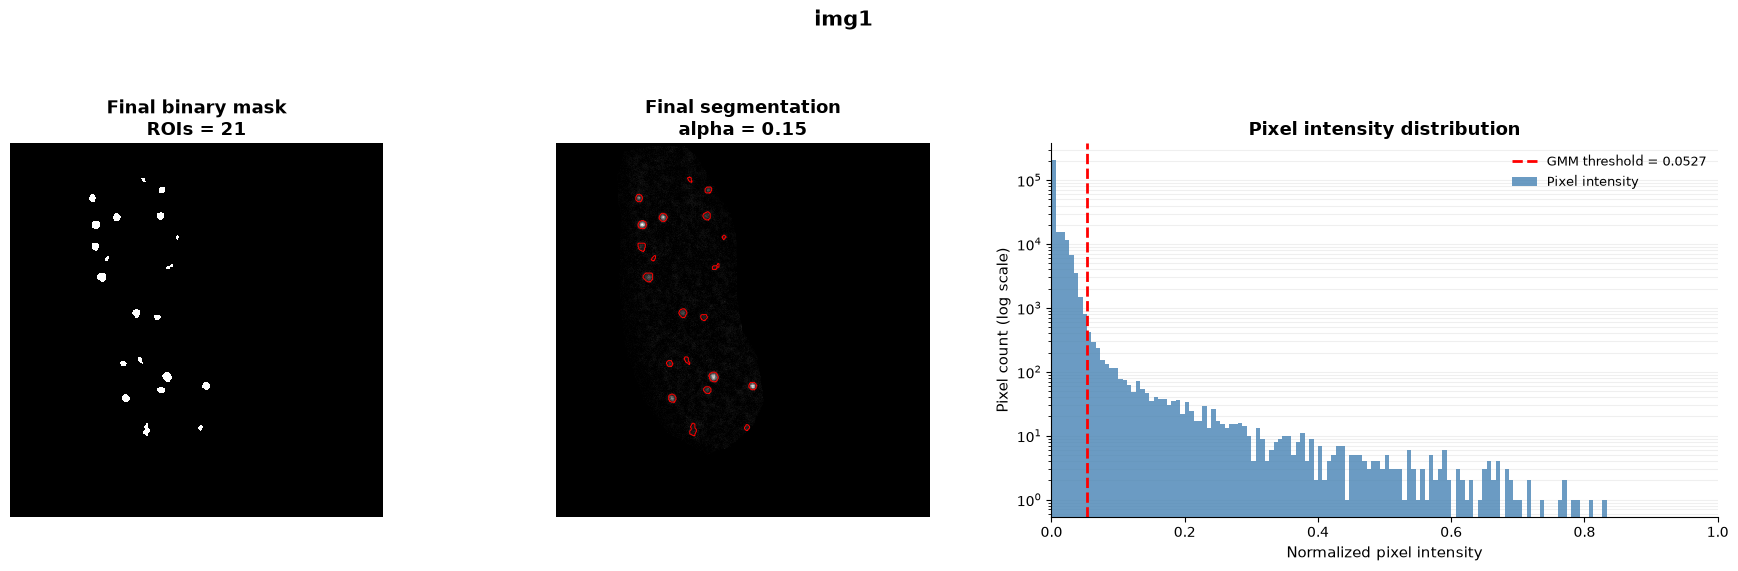


Processing: img2


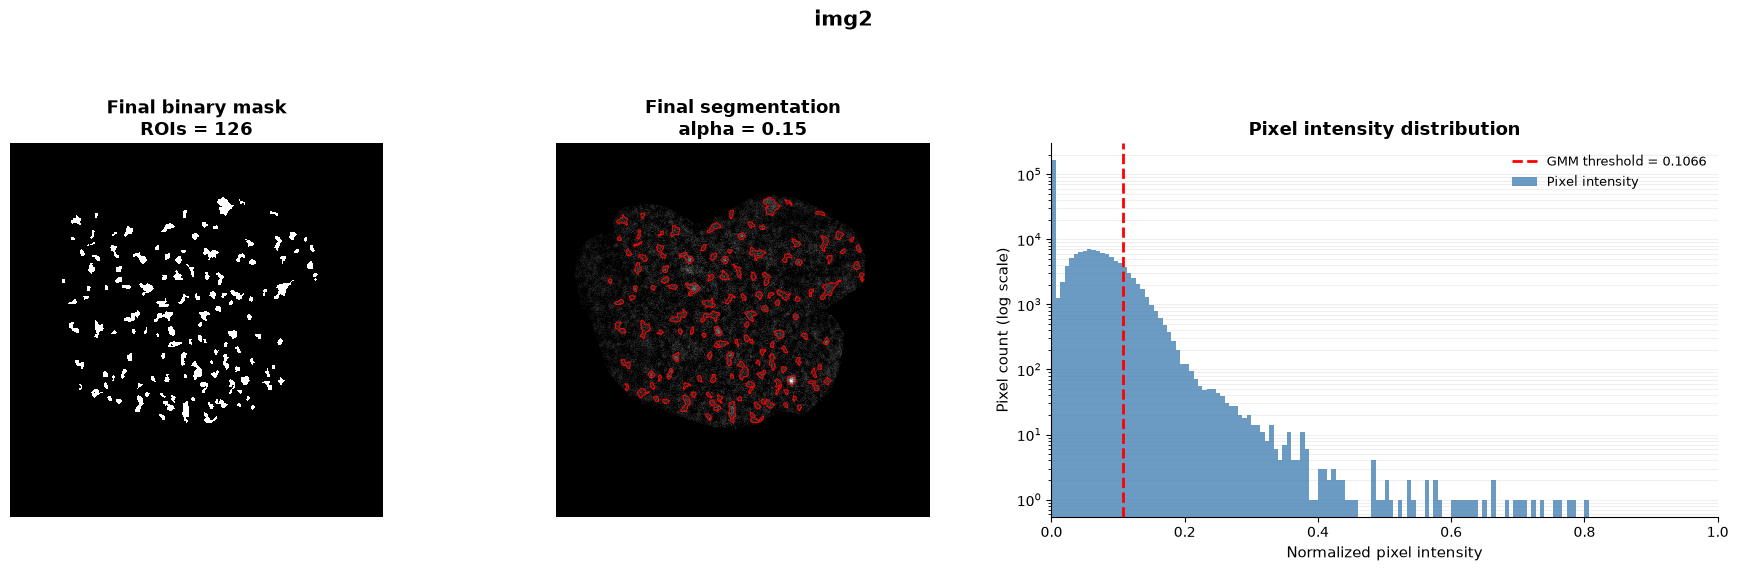


Processing: img3


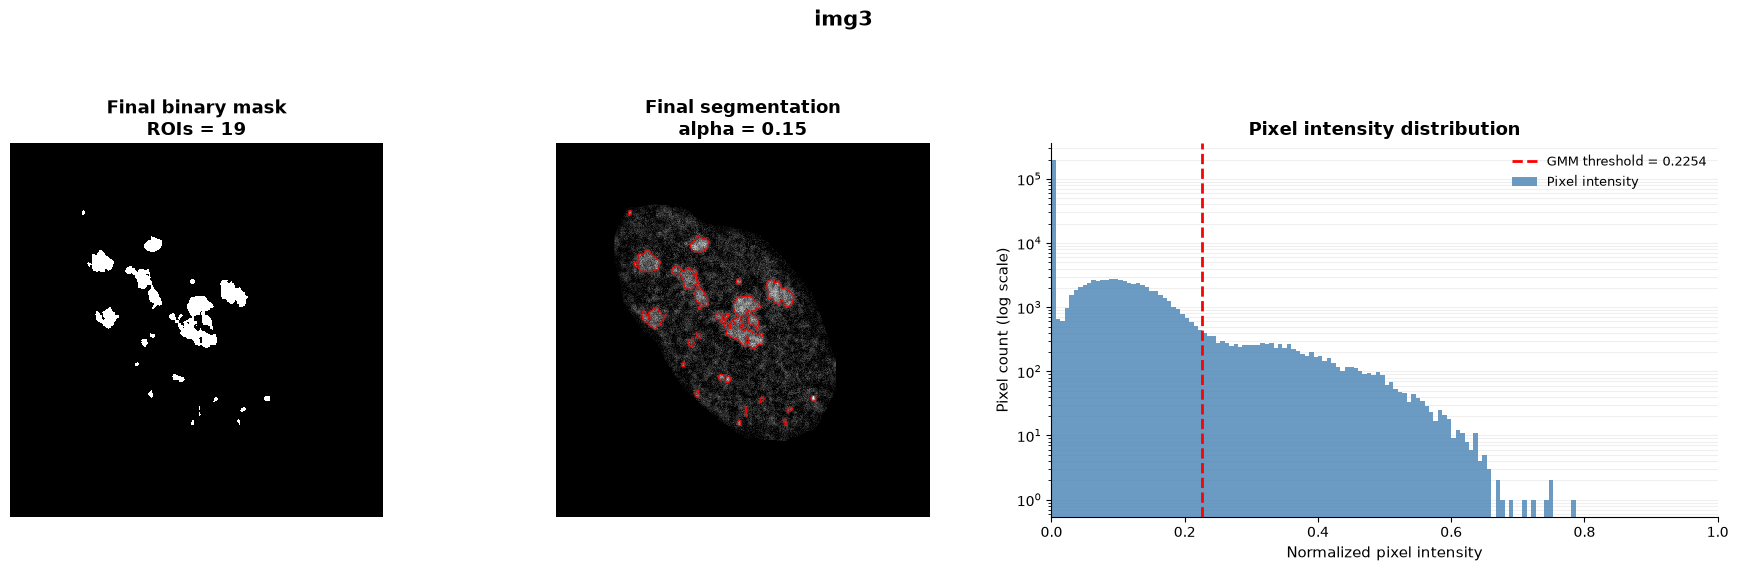


Processing: img4


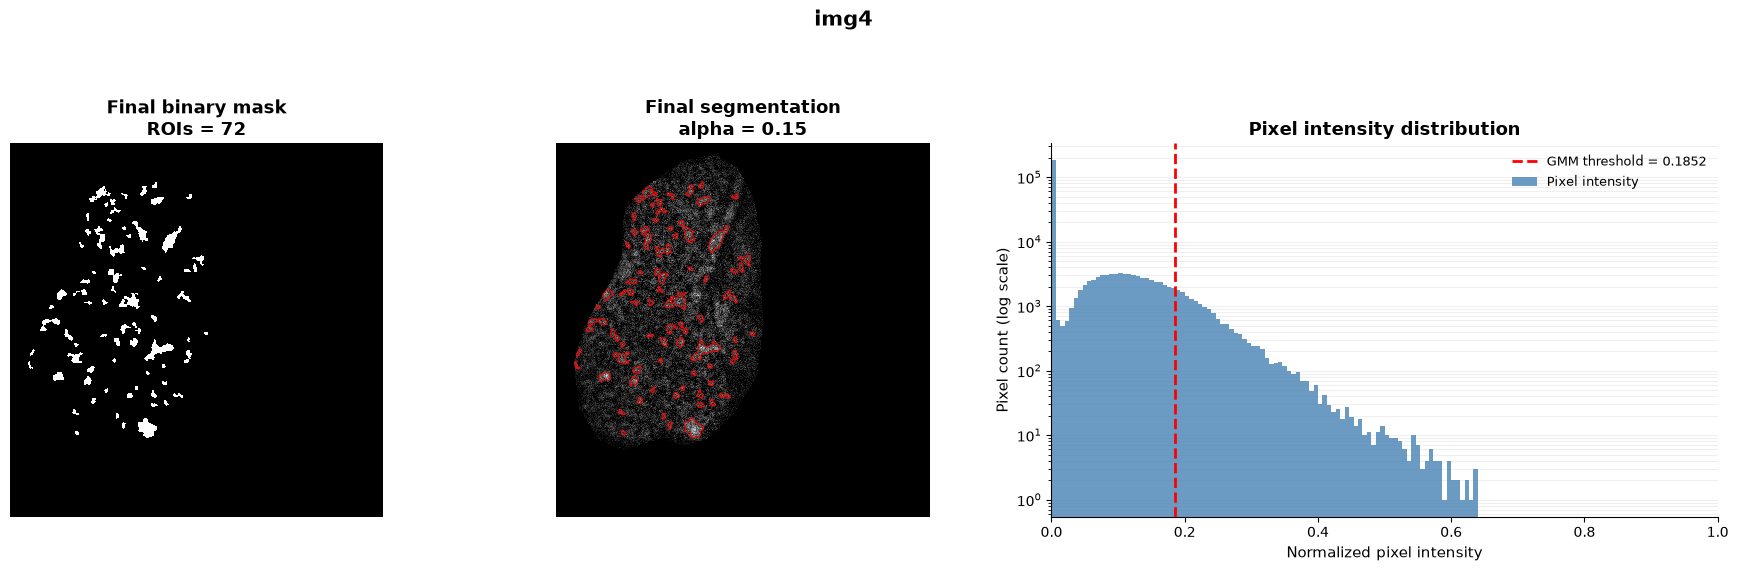


GMM SEGMENTATION RESULTS:
image  GMM_threshold  initial_ROIs  refined_ROIs  initial_area_px  refined_area_px  GMM_mean_1  GMM_mean_2  GMM_mean_3  area_reduction_percent
 img1         0.0527            28            21             2751             1521         0.0      0.0187      0.1260                 44.7110
 img2         0.1066           258           126            19358             8378         0.0      0.0609      0.1070                 56.7207
 img3         0.2254            50            19             9164             5911         0.0      0.1030      0.3225                 35.4976
 img4         0.1852           174            72            17616             5862         0.0      0.1057      0.2047                 66.7234


In [10]:
# =====================================================
# 10. PROCESS ALL FOUR IMAGES
# =====================================================

results = {}
summary = []

for image_path in image_paths:

    image_name = Path(image_path).stem

    print(f"\nProcessing: {image_name}")

    result = process_image_gmm(
        image_path,
        plot=show_plots,
        save_path=output_dir / f"{image_name}_GMM_refined.png"
    )

    results[image_name] = result

    summary.append({
        "image": image_name,
        "GMM_threshold": result["threshold"],
        "initial_ROIs": result["n_initial"],
        "refined_ROIs": result["n_refined"],
        "initial_area_px": int(result["initial_mask"].sum()),
        "refined_area_px": int(result["refined_mask"].sum()),
        "GMM_mean_1": result["means"][0],
        "GMM_mean_2": result["means"][1],
        "GMM_mean_3": result["means"][2]
            if len(result["means"]) > 2 else np.nan
    })

    # Save initial binary mask
    io.imsave(
        output_dir / f"{image_name}_initial_mask.tif",
        (result["initial_mask"] * 255).astype(np.uint8),
        check_contrast=False
    )

    # Save refined binary mask
    io.imsave(
        output_dir / f"{image_name}_refined_mask.tif",
        (result["refined_mask"] * 255).astype(np.uint8),
        check_contrast=False
    )

    # Save refined labels
    io.imsave(
        output_dir / f"{image_name}_refined_labels.tif",
        result["refined_labels"].astype(np.int32),
        check_contrast=False
    )


# =====================================================
# 11. SUMMARY
# =====================================================

summary_df = pd.DataFrame(summary)

summary_df["area_reduction_percent"] = (
    100 * (
        1
        - summary_df["refined_area_px"]
        / summary_df["initial_area_px"].replace(0, np.nan)
    )
)

print("\nGMM SEGMENTATION RESULTS:")
print(summary_df.round(4).to_string(index=False))

summary_df.to_csv(
    output_dir / "GMM_refined_summary.csv",
    index=False
)